In [2]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, UpSampling1D

In [4]:
# Load the ECG dataset
data = pd.read_csv("ecg.csv", header=None)

print(data.shape)
print(data.head())

(4998, 141)
        0         1         2         3         4         5         6    \
0 -0.112522 -2.827204 -3.773897 -4.349751 -4.376041 -3.474986 -2.181408   
1 -1.100878 -3.996840 -4.285843 -4.506579 -4.022377 -3.234368 -1.566126   
2 -0.567088 -2.593450 -3.874230 -4.584095 -4.187449 -3.151462 -1.742940   
3  0.490473 -1.914407 -3.616364 -4.318823 -4.268016 -3.881110 -2.993280   
4  0.800232 -0.874252 -2.384761 -3.973292 -4.338224 -3.802422 -2.534510   

        7         8         9    ...       131       132       133       134  \
0 -1.818286 -1.250522 -0.477492  ...  0.792168  0.933541  0.796958  0.578621   
1 -0.992258 -0.754680  0.042321  ...  0.538356  0.656881  0.787490  0.724046   
2 -1.490659 -1.183580 -0.394229  ...  0.886073  0.531452  0.311377 -0.021919   
3 -1.671131 -1.333884 -0.965629  ...  0.350816  0.499111  0.600345  0.842069   
4 -1.783423 -1.594450 -0.753199  ...  1.148884  0.958434  1.059025  1.371682   

        135       136       137       138       139  140

In [5]:
# Separate signals and labels
X = data.iloc[:, :-1].values
y = data.iloc[:, -1].values

print("ECG signals:", X.shape)
print("Labels:", y.shape)

ECG signals: (4998, 140)
Labels: (4998,)


In [6]:
# Normalize the ECG signals
scaler = MinMaxScaler()

X = scaler.fit_transform(X)

In [7]:
# Select normal ECG signals
X_normal = X[y == 0]

print("Normal ECG signals:", X_normal.shape)

Normal ECG signals: (2079, 140)


In [8]:
# Select normal ECG signals
X_train, X_val = train_test_split(
    X_normal,
    test_size=0.2,
    random_state=42
)

In [9]:
# Reshape the data
X_train = X_train.reshape(X_train.shape[0], 140, 1)
X_val = X_val.reshape(X_val.shape[0], 140, 1)
X_test = X.reshape(X.shape[0], 140, 1)

In [10]:
# Build the Autoencoder
input_layer = Input(shape=(140, 1))

# Encoder
x = Conv1D(16, 3, activation="relu", padding="same")(input_layer)
x = MaxPooling1D(2, padding="same")(x)

x = Conv1D(8, 3, activation="relu", padding="same")(x)
encoded = MaxPooling1D(2, padding="same")(x)

# Decoder
x = Conv1D(8, 3, activation="relu", padding="same")(encoded)
x = UpSampling1D(2)(x)

x = Conv1D(16, 3, activation="relu", padding="same")(x)
x = UpSampling1D(2)(x)

decoded = Conv1D(1, 3, activation="sigmoid", padding="same")(x)

autoencoder = Model(input_layer, decoded)

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 140, 1)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d (Conv1D)                      │ (None, 140, 16)             │              64 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d (MaxPooling1D)         │ (None, 70, 16)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_1 (Conv1D)                    │ (None, 70, 8)               │             392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_1 (MaxPooling1D)       │ (None, 35, 8)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_2 (Conv1D)                    │ (None, 35, 8)               │             200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling1d (UpSampling1D)         │ (None, 70, 8)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_3 (Conv1D)                    │ (None, 70, 16)              │             400 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling1d_1 (UpSampling1D)       │ (None, 140, 16)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_4 (Conv1D)                    │ (None, 140, 1)              │              49 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,105 (4.32 KB)

 Trainable params: 1,105 (4.32 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Compile the model
autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

In [12]:
# Train the Autoencoder
history = autoencoder.fit(
    X_train,
    X_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, X_val),
    shuffle=True
)

Epoch 1/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - loss: 0.0186 - val_loss: 0.0133
Epoch 2/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.0104 - val_loss: 0.0062
Epoch 3/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0040 - val_loss: 0.0026
Epoch 4/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0021 - val_loss: 0.0018
Epoch 5/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0015 - val_loss: 0.0012
Epoch 6/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0011 - val_loss: 0.0010
Epoch 7/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0010 - val_loss: 9.5499e-04
Epoch 8/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 9.5856e-04 - val_loss: 9.1151e-04
Epoch 9/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 9.0895e-04 - val_loss: 8.5853e-04
Epoch 10/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 8.6221e-04 - val_loss: 8.1816e-04
Epoch 11/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 8.2098e-04 - val_loss: 7.8288e-04
Epoch 12/20
52/52 ━━━━━━━━━

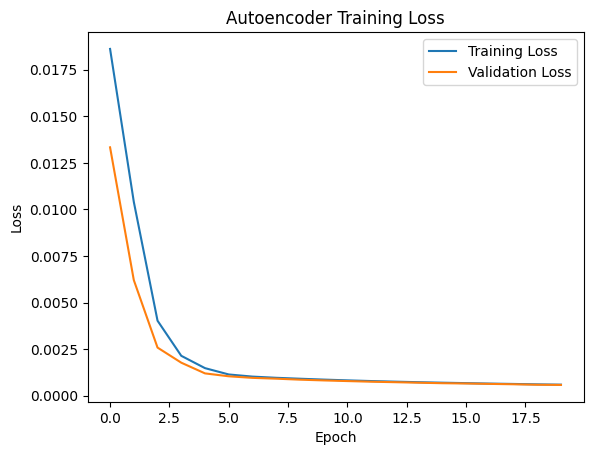

In [13]:
# 11. Plot training loss
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Autoencoder Training Loss")
plt.legend()
plt.show()

In [14]:
# Reconstruct test ECG signals
reconstructed = autoencoder.predict(X_test)

157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step


In [15]:
# Calculate reconstruction error
errors = np.mean(
    np.square(X_test - reconstructed),
    axis=(1, 2)
)

print(errors)

[0.00085375 0.00089809 0.00116198 ... 0.00054245 0.00059094 0.00053016]


In [16]:
# Set the threshold
val_reconstructed = autoencoder.predict(X_val)

val_errors = np.mean(
    np.square(X_val - val_reconstructed),
    axis=(1, 2)
)

threshold = np.percentile(val_errors, 95)

print("Threshold:", threshold)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
Threshold: 0.0008671673603589763


In [17]:
# Detect anomalies
predictions = (errors > threshold).astype(int)

print("Predictions:", predictions)

Predictions: [0 1 1 ... 0 0 0]


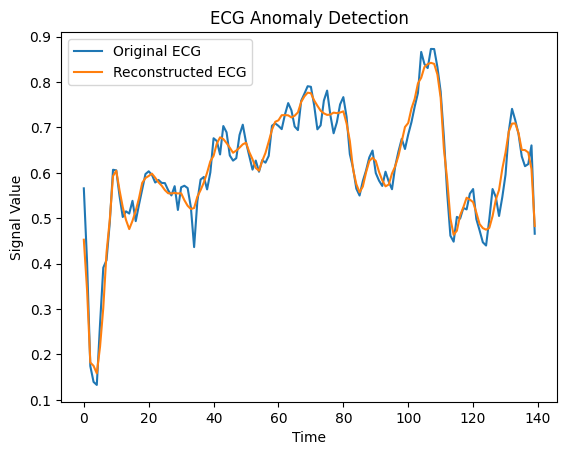

Reconstruction Error: 0.0008537472859799395
Normal ECG


In [18]:
# Display an ECG signal
i = 0

plt.plot(X_test[i].flatten(), label="Original ECG")
plt.plot(reconstructed[i].flatten(), label="Reconstructed ECG")

plt.title("ECG Anomaly Detection")
plt.xlabel("Time")
plt.ylabel("Signal Value")
plt.legend()
plt.show()

print("Reconstruction Error:", errors[i])

if predictions[i] == 1:
    print("Anomaly Detected")
else:
    print("Normal ECG")